# Support Ticket Classifier: TF-IDF baseline vs fine-tuned BERT

Route English customer support tickets to the right **queue** (team).

1. Load and explore the data
2. Train a **TF-IDF + logistic regression** baseline
3. Fine-tune **BERT** (`bert-base-uncased`) with Hugging Face
4. Compare both on the same held-out test set (macro-F1, confusion matrix)

**Runtime:** in Colab, go to *Runtime → Change runtime type → T4 GPU* before running.

In [1]:
!pip -q install -U transformers datasets accelerate evaluate scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## 1. Load and explore the data

In [2]:
import numpy as np, pandas as pd
from datasets import load_dataset

raw = load_dataset("Tobi-Bueck/customer-support-tickets", split="train").to_pandas()
print("All rows:", len(raw))
print(raw["language"].value_counts())

df = raw[raw["language"] == "en"].copy()
df["text"] = (df["subject"].fillna("") + ". " + df["body"].fillna("")).str.strip(". ").str.strip()
df = df[(df["text"].str.len() > 10) & df["queue"].notna()].drop_duplicates(subset=["text"])
# Keep queues with enough examples for a fair stratified split
MIN_PER_CLASS = 50
counts = df["queue"].value_counts()
dropped = counts[counts < MIN_PER_CLASS]
df = df[df["queue"].isin(counts[counts >= MIN_PER_CLASS].index)]
print(f"Dropped {len(dropped)} rare queues ({dropped.sum()} tickets)")
print("English tickets after cleaning:", len(df), "| queues:", df["queue"].nunique())
df["queue"].value_counts()

README.md:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

aa_dataset-tickets-multi-lang-5-2-50-ver(…): reconstructing file:   0%|          |  0.00B / 26.0MB            

aa_dataset-tickets-multi-lang-5-2-50-ver(…): downloading bytes:           |  0.00B            

(…)set-tickets-german_normalized_50_5_2.csv:   0%|          | 0.00/8.33M [00:00<?, ?B/s]

dataset-tickets-multi-lang-4-20k.csv: reconstructing file:   0%|          |  0.00B / 18.8MB            

dataset-tickets-multi-lang-4-20k.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/61765 [00:00<?, ? examples/s]

All rows: 61765
language
de    33504
en    28261
Name: count, dtype: int64
Dropped 0 rare queues (0 tickets)
English tickets after cleaning: 23745 | queues: 10


,count
queue,
Technical Support,6857
Product Support,4430
Customer Service,3570
IT Support,2832
Billing and Payments,2419
Returns and Exchanges,1173
Service Outages and Maintenance,937
Sales and Pre-Sales,724
Human Resources,461


In [3]:
df["text"].str.split().str.len().describe()

,text
count,23745.000000
mean,61.182312
std,32.024658
min,2.000000
25%,35.000000
50%,60.000000
75%,84.000000
max,276.000000


## 2. Same train / validation / test split for both models

In [4]:
from sklearn.model_selection import train_test_split

SEED = 42
train_df, temp_df = train_test_split(df[["text", "queue"]], test_size=0.2, stratify=df["queue"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["queue"], random_state=SEED)

labels = sorted(df["queue"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}  classes={len(labels)}")

train=18996  val=2374  test=2375  classes=10


## 3. Baseline: TF-IDF + logistic regression

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, f1_score, accuracy_score

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)
baseline.fit(train_df["text"], train_df["queue"])
base_pred = baseline.predict(test_df["text"])

base_scores = {
    "accuracy": accuracy_score(test_df["queue"], base_pred),
    "macro_f1": f1_score(test_df["queue"], base_pred, average="macro"),
    "weighted_f1": f1_score(test_df["queue"], base_pred, average="weighted"),
}
print(base_scores)
print(classification_report(test_df["queue"], base_pred, digits=3, zero_division=0))

{'accuracy': 0.504421052631579, 'macro_f1': 0.5072167121890383, 'weighted_f1': 0.5053611987662092}
                                 precision    recall  f1-score   support

           Billing and Payments      0.748     0.748     0.748       242
               Customer Service      0.446     0.440     0.443       357
                General Inquiry      0.400     0.412     0.406        34
                Human Resources      0.525     0.674     0.590        46
                     IT Support      0.400     0.516     0.451       283
                Product Support      0.501     0.391     0.439       443
          Returns and Exchanges      0.372     0.576     0.452       118
            Sales and Pre-Sales      0.343     0.639     0.447        72
Service Outages and Maintenance      0.508     0.660     0.574        94
              Technical Support      0.595     0.466     0.523       686

                       accuracy                          0.504      2375
                      m

## 4. Fine-tune BERT

In [6]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

MODEL = "bert-base-uncased"
tok = AutoTokenizer.from_pretrained(MODEL)

def to_ds(frame):
    d = Dataset.from_pandas(frame.assign(label=frame["queue"].map(label2id))[["text", "label"]], preserve_index=False)
    return d.map(lambda b: tok(b["text"], truncation=True, max_length=256), batched=True)

train_ds, val_ds, test_ds = to_ds(train_df), to_ds(val_df), to_ds(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(labels), id2label=id2label, label2id=label2id)

# Class weights: rare queues (e.g. General Inquiry) count more in the loss,
# mirroring class_weight="balanced" in the baseline so the comparison is fair.
counts = train_df["queue"].map(label2id).value_counts().sort_index().values
class_w = torch.tensor(len(train_df) / (len(labels) * counts), dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels_t = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits.float(), labels_t, weight=class_w.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments(
    output_dir="bert-tickets",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=6,
    weight_decay=0.01,
    warmup_steps=700,          # ~10% of 7,128 training steps
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
trainer.train()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/18996 [00:00<?, ? examples/s]

Map:   0%|          | 0/2374 [00:00<?, ? examples/s]

... (11 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=7128, training_loss=1.1772391590071314, metrics={'train_runtime': 1144.1127, 'train_samples_per_second': 99.62, 'train_steps_per_second': 6.23, 'total_flos': 9044099274763056.0, 'train_loss': 1.1772391590071314, 'epoch': 6.0})

## 5. Compare on the held-out test set

In [7]:
out = trainer.predict(test_ds)
bert_pred = [id2label[i] for i in out.predictions.argmax(-1)]

bert_scores = {
    "accuracy": accuracy_score(test_df["queue"], bert_pred),
    "macro_f1": f1_score(test_df["queue"], bert_pred, average="macro"),
    "weighted_f1": f1_score(test_df["queue"], bert_pred, average="weighted"),
}
results = pd.DataFrame({"TF-IDF + LogReg": base_scores, "BERT (fine-tuned)": bert_scores}).T.round(3)
results

,accuracy,macro_f1,weighted_f1
TF-IDF + LogReg,0.504,0.507,0.505
BERT (fine-tuned),0.531,0.579,0.528


In [8]:
print(classification_report(test_df["queue"], bert_pred, digits=3, zero_division=0))

                                 precision    recall  f1-score   support

           Billing and Payments      0.770     0.831     0.799       242
               Customer Service      0.460     0.501     0.480       357
                General Inquiry      0.500     0.412     0.452        34
                Human Resources      0.723     0.739     0.731        46
                     IT Support      0.402     0.572     0.472       283
                Product Support      0.471     0.386     0.424       443
          Returns and Exchanges      0.550     0.610     0.578       118
            Sales and Pre-Sales      0.701     0.653     0.676        72
Service Outages and Maintenance      0.654     0.723     0.687        94
              Technical Support      0.536     0.455     0.492       686

                       accuracy                          0.531      2375
                      macro avg      0.577     0.588     0.579      2375
                   weighted avg      0.534     0.

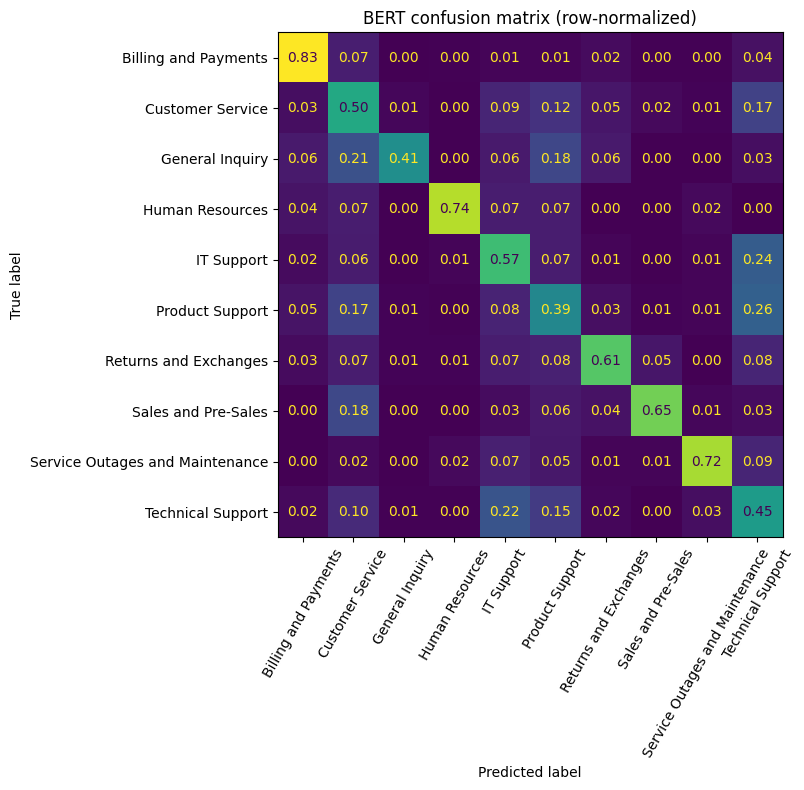

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(test_df["queue"], bert_pred, labels=labels,
                                        xticks_rotation=60, normalize="true", values_format=".2f", ax=ax, colorbar=False)
ax.set_title("BERT confusion matrix (row-normalized)")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

## 6. Try it on a new ticket

In [10]:
from transformers import pipeline
clf = pipeline("text-classification", model=trainer.model, tokenizer=tok, device=0 if torch.cuda.is_available() else -1)
clf("I was charged twice for my subscription this month and need a refund.")

[{'label': 'Billing and Payments', 'score': 0.9944247007369995}]

## 7. Save the model and results

In [11]:
import json, shutil
trainer.save_model("model"); tok.save_pretrained("model")
results.to_csv("results.csv")
json.dump({"labels": labels, "min_per_class": MIN_PER_CLASS, "seed": SEED,
           "train": len(train_df), "val": len(val_df), "test": len(test_df)}, open("run_info.json", "w"), indent=2)
# Sanity check: the saved model must reproduce the test score
check = AutoModelForSequenceClassification.from_pretrained("model")
chk = Trainer(model=check, args=TrainingArguments("tmp", per_device_eval_batch_size=32, report_to="none"),
              data_collator=DataCollatorWithPadding(tok)).predict(test_ds)
print("Reloaded model macro-F1:", round(f1_score(out.label_ids, chk.predictions.argmax(-1), average="macro"), 3))
shutil.make_archive("ticket_model", "zip", "model")
print(results); print("Saved: model/, ticket_model.zip, results.csv, run_info.json, confusion_matrix.png")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reloaded model macro-F1: 0.58
                   accuracy  macro_f1  weighted_f1
TF-IDF + LogReg       0.504     0.507        0.505
BERT (fine-tuned)     0.531     0.579        0.528
Saved: model/, ticket_model.zip, results.csv, run_info.json, confusion_matrix.png
